In [13]:
##########################
##-Installing libraries-##
##########################

%%capture
!pip install -q numpy pandas matplotlib plotly

In [14]:
#########################
##-Importing libraries-##
#########################

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from matplotlib.colors import to_rgba
from plotly.subplots import make_subplots

In [15]:
####################
##-Plotting style-##
####################

l = 8.25 / 2.54

plt.rc('figure', figsize=(l, l), dpi=500)
plt.rc('font', size=8, family='sans-serif')
plt.rc('lines', linewidth=1)
plt.rc('legend', fontsize=5)
plt.rc('svg', fonttype='none')
plt.rc('pdf', fonttype=42)

metal_order = ['Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu']

metal_colors = {
    'Cr': '#8A99C7',
    'Mn': '#9C7AC7',
    'Fe': '#E06633',
    'Co': '#F090A0',
    'Ni': '#50D050',
    'Cu': '#C88033',
}

In [16]:
######################
##-Read predictions-##
######################

predictions = pd.read_csv('final_inputs_v21/predictions.csv')

results = predictions.pivot(
    index=['name', 'ads_site'],
    columns='target',
    values='predicted_eV',
).reset_index()

results.columns.name = None

##-The source G_* columns contain electronic adsorption energies
results = results.rename(columns={
    'G_OH': 'E_ads_OH',
    'G_O': 'E_ads_O',
    'G_OOH': 'E_ads_OOH',
})

energy_columns = ['E_ads_OH', 'E_ads_O', 'E_ads_OOH']
results[energy_columns] = results[energy_columns].apply(pd.to_numeric)

##-Read catalyst components from the name
parts = results['name'].str.split('_', expand=True)

results['metal1'] = parts[1]
results['metal2'] = parts[2]
results['dialdehyde'] = parts[3]
results['diamine'] = parts[4]
results['bridge'] = parts[5].str[-2:]

results['metal'] = np.where(
    results['ads_site'] == 'metal1',
    results['metal1'],
    results['metal2'],
)

results['other_metal'] = np.where(
    results['ads_site'] == 'metal1',
    results['metal2'],
    results['metal1'],
)


In [17]:
#################################
##-Filtering and free energies-##
#################################

results['retained'] = (
    (results['E_ads_OH'] >= 0) &
    (results['E_ads_O'] <= 4.92)
)

results['G_OH'] = results['E_ads_OH'] + 0.05
results['G_O'] = results['E_ads_O'] + 0.05
results['G_OOH'] = results['E_ads_OOH'] + 0.10

In [18]:
##########################################
##-Limiting potential and overpotential-##
##########################################

steps = pd.DataFrame({
    'O2 to OOH': 4.92 - results['G_OOH'],
    'OOH to O': results['G_OOH'] - results['G_O'],
    'O to OH': results['G_O'] - results['G_OH'],
    'OH to water': results['G_OH'],
})

results['U_L'] = steps.min(axis=1)
results['overpotential'] = 1.23 - results['U_L']
results['potential_determining_step'] = steps.idxmin(axis=1)

data = results[results['retained']].copy()

print(f'Total: {len(results)} pathways, {results["name"].nunique()} catalysts')
print(f'Retained: {len(data)} pathways, {data["name"].nunique()} catalysts')

data.sort_values('overpotential')[
    ['name', 'ads_site', 'metal', 'overpotential']
].head(10)

Total: 1979 pathways, 1117 catalysts
Retained: 1924 pathways, 1098 catalysts


,name,ads_site,metal,overpotential
1165,KMC_Fe_Fe_A9_B1_NNNNOO_q2,metal1,Fe,0.243796
1120,KMC_Fe_Fe_A1_B1_NNNNSS_q2,metal1,Fe,0.249336
1639,KMC_Mn_Fe_A9_B1_NNNNSS_q2,metal2,Fe,0.249776
1149,KMC_Fe_Fe_A5_B1_NNNNSS_q2,metal1,Fe,0.253816
527,KMC_Cr_Fe_A2_B1_NNNNSS_q2,metal2,Fe,0.254634
1523,KMC_Mn_Fe_A1_B1_NNNNSS_q2,metal2,Fe,0.257364
507,KMC_Cr_Fe_A1_B1_NNNNSS_q2,metal2,Fe,0.258572
1140,KMC_Fe_Fe_A4_B1_NNNNSS_q2,metal1,Fe,0.259055
1591,KMC_Mn_Fe_A5_B1_NNNNSS_q2,metal2,Fe,0.259365
1158,KMC_Fe_Fe_A6_B1_NNNNSS_q2,metal1,Fe,0.259567


In [19]:
###########################
##-Fit scaling relations-##
###########################

fit_O = np.polyfit(data['G_OH'], data['G_O'], 1)
fit_OOH = np.polyfit(data['G_OH'], data['G_OOH'], 1)

x_min = data['G_OH'].min()
x_max = data['G_OH'].max()
pad = 0.08 * (x_max - x_min)

x = np.linspace(x_min - pad, x_max + pad, 500)

y_O = np.polyval(fit_O, x)
y_OOH = np.polyval(fit_OOH, x)

eta = 1.23 - np.min([4.92 - y_OOH, y_OOH - y_O, y_O - x, x], axis=0)
ideal_eta = 1.23 - np.minimum(x, 4.92 - (x + 2.46))

eta_max = np.ceil(
    max(data['overpotential'].max(), eta.max(), ideal_eta.max()) / 0.2
) * 0.2

pd.DataFrame({
    'Relation': ['O vs OH', 'OOH vs OH'],
    'Slope': [fit_O[0], fit_OOH[0]],
    'Intercept (eV)': [fit_O[1], fit_OOH[1]],
})

,Relation,Slope,Intercept (eV)
0,O vs OH,1.718432,1.187953
1,OOH vs OH,0.673819,3.038883


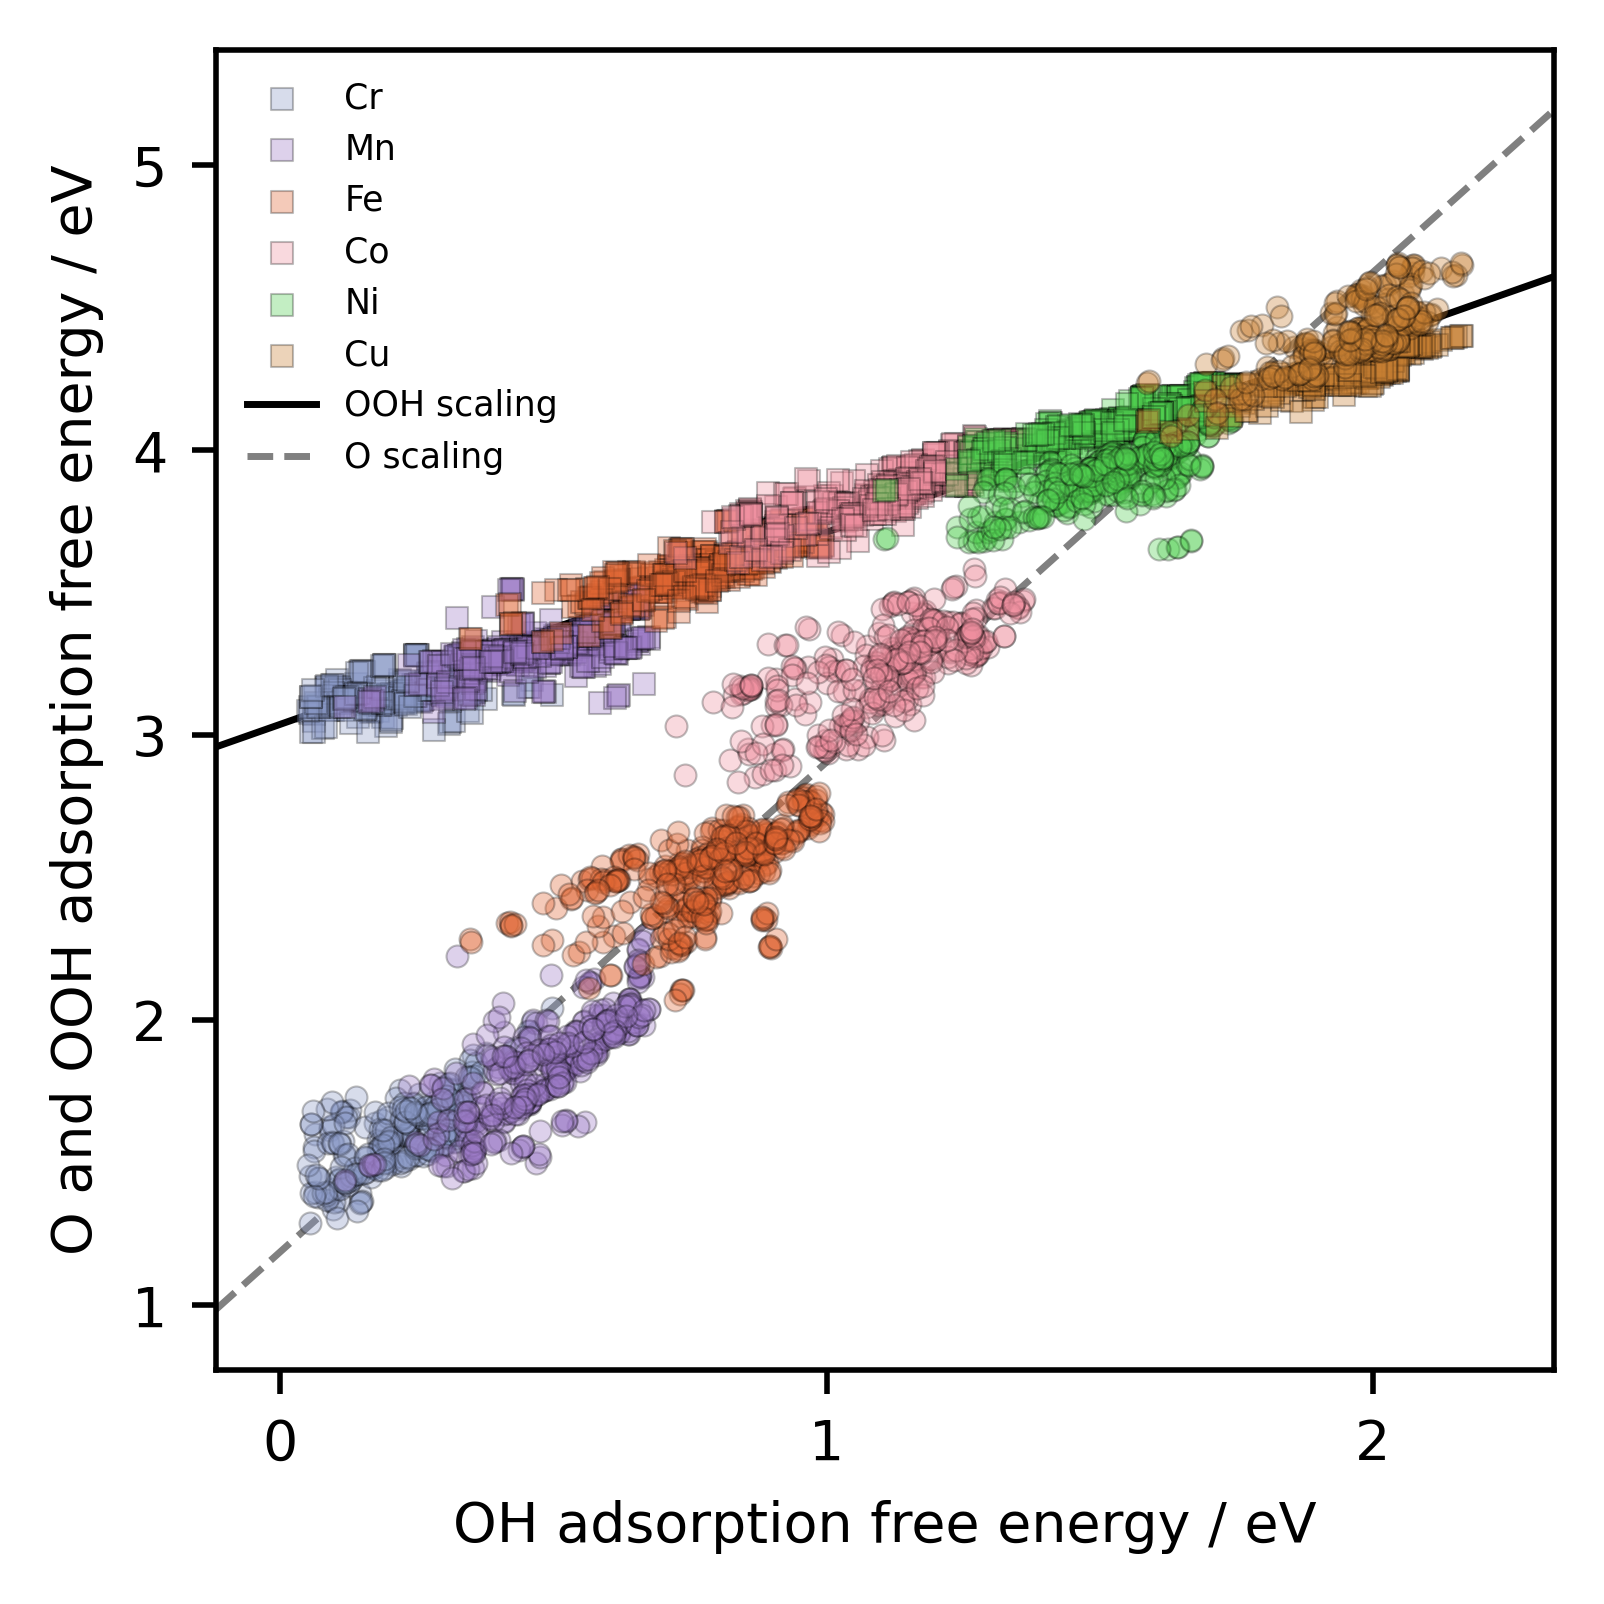

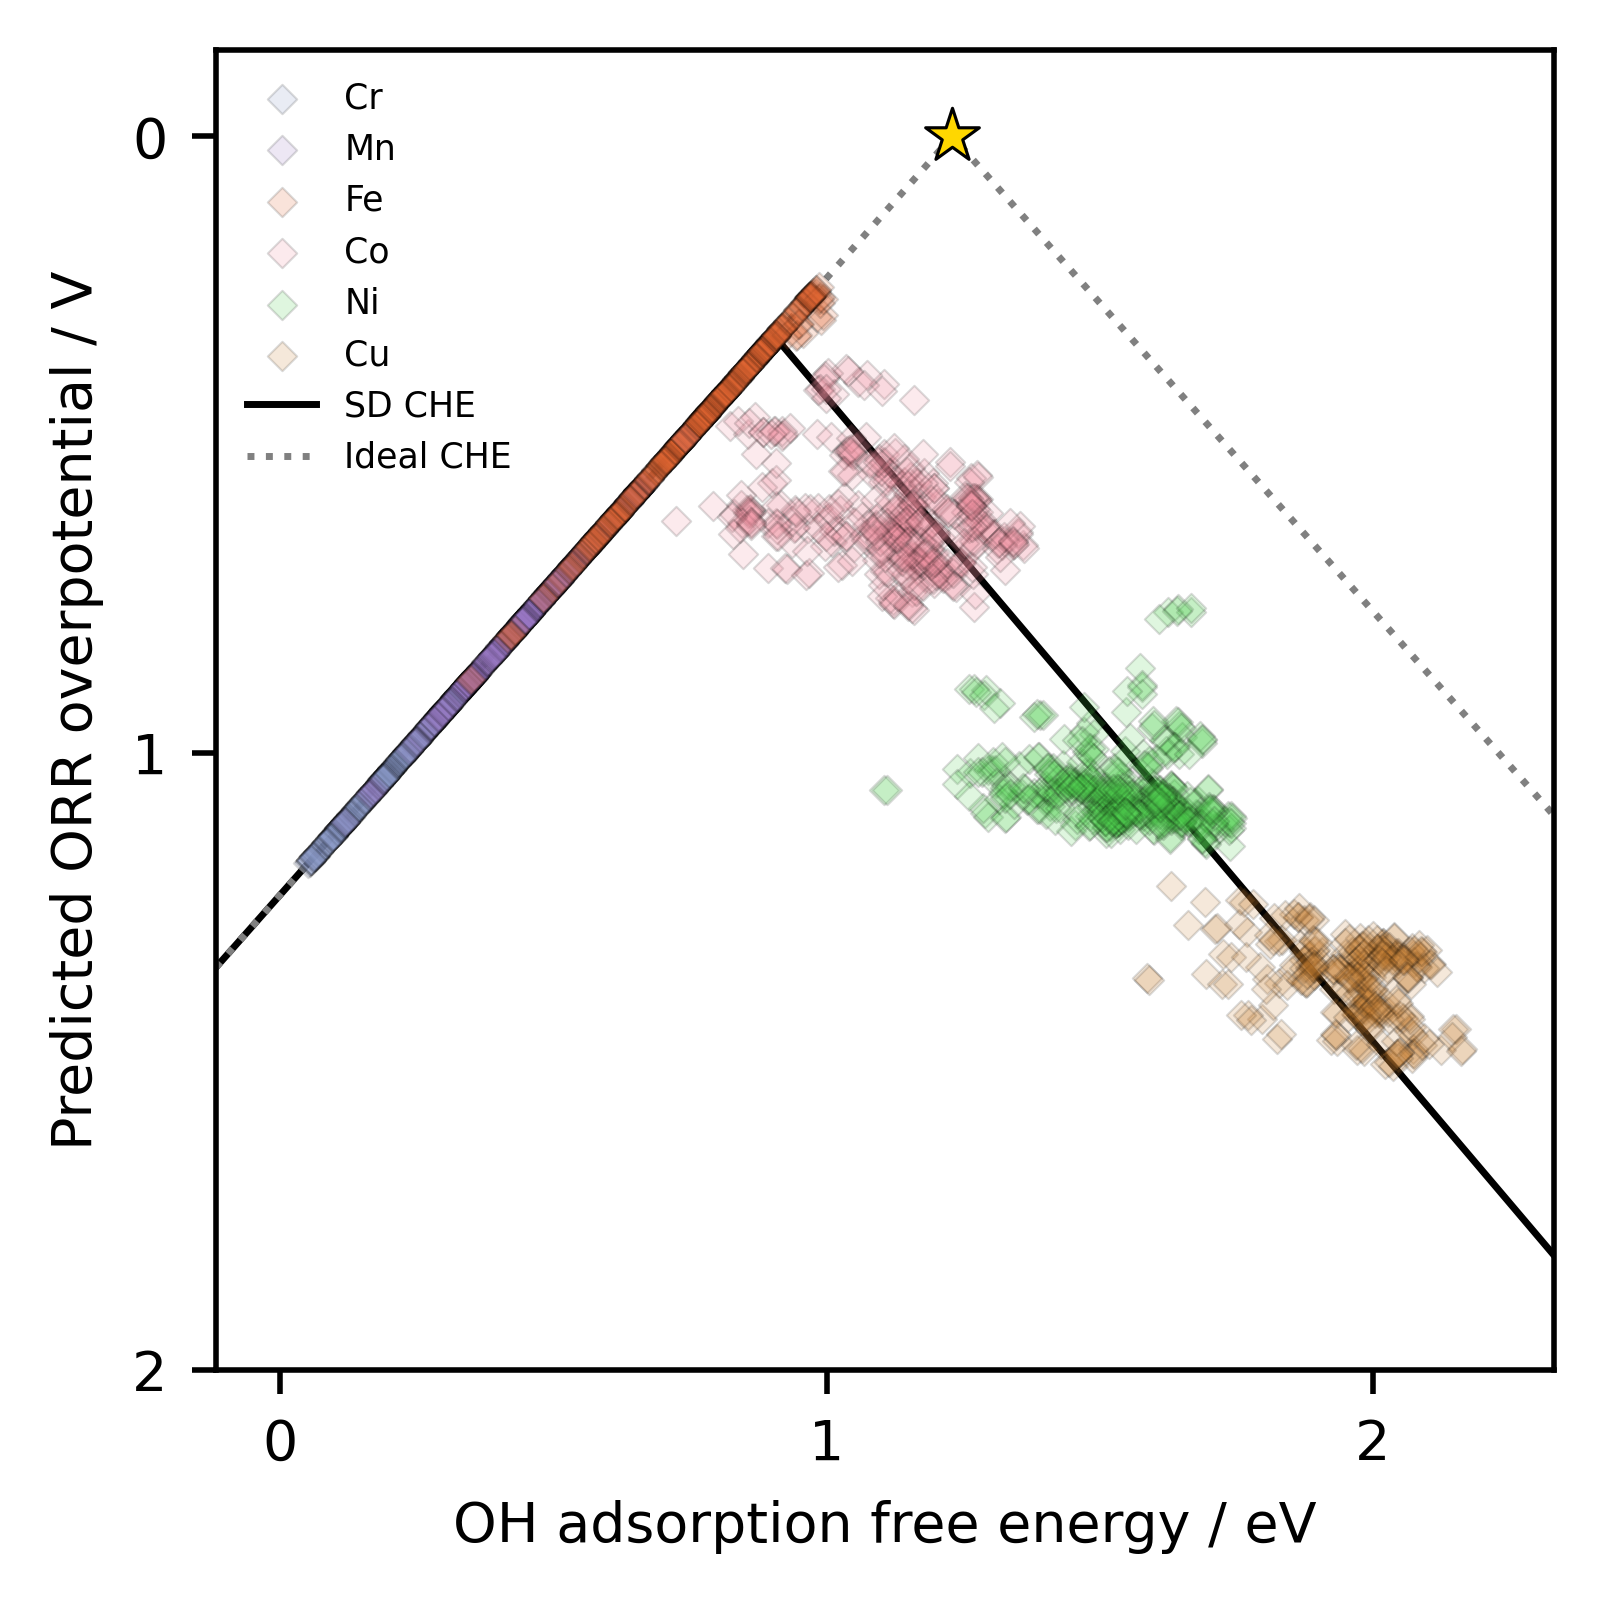

In [20]:
########################
##-Matplotlib figures-##
########################

##-Scaling relations
plt.figure()

for metal in metal_order:
    group = data[data['metal'] == metal]

    for column, marker in [('G_OOH', 's'), ('G_O', 'o')]:
        plt.scatter(
            group['G_OH'], group[column],
            marker=marker, s=10,
            facecolors=[to_rgba(metal_colors[metal], 0.34)],
            edgecolors=[to_rgba('black', 0.26)],
            linewidths=0.3,
            label=metal if column == 'G_OOH' else None,
            zorder=2,
        )

plt.plot(x, y_OOH, color='black', label='OOH scaling', zorder=1)
plt.plot(x, y_O, '--', color='gray', label='O scaling', zorder=1)

plt.xlabel('OH adsorption free energy / eV')
plt.ylabel('O and OOH adsorption free energy / eV')
plt.xticks([0, 1, 2])
plt.yticks([1, 2, 3, 4, 5])
plt.xlim(x[0], x[-1])
plt.legend(loc='upper left', framealpha=0)
plt.tight_layout()

# plt.savefig('Figure_4_scaling.png', dpi=600)
plt.show()


##-ORR volcano
plt.figure()

for metal in metal_order:
    group = data[data['metal'] == metal]

    plt.scatter(
        group['G_OH'], group['overpotential'],
        marker='D', s=9,
        facecolors=[to_rgba(metal_colors[metal], 0.18)],
        edgecolors=[to_rgba('black', 0.14)],
        linewidths=0.3,
        label=metal, zorder=2,
    )

plt.plot(x, eta, color='black', label='SD CHE', zorder=1)
plt.plot(x, ideal_eta, ':', color='gray', label='Ideal CHE', zorder=1)
plt.scatter(
    1.23, 0, color='gold', marker='*', s=66,
    edgecolors='black', linewidths=0.45, zorder=3,
)

plt.xlabel('OH adsorption free energy / eV')
plt.ylabel('Predicted ORR overpotential / V')
plt.xticks([0, 1, 2])
plt.yticks(np.arange(0, eta_max + 0.01, 1))
plt.xlim(x[0], x[-1])
plt.ylim(eta_max, -0.14)
plt.legend(loc='upper left', framealpha=0)
plt.tight_layout()

# plt.savefig('Figure_4_volcano.png', dpi=600)
plt.show()